# Discovering laws 4: Deriving the precession

*Learning path: discovering physical laws, part 4 of 4.* [Index](README.md) · Previous: [Mercury doesn't fit](03-mercury.ipynb)

In [part 3](03-mercury.ipynb) the data asked for an extra term in the orbit equation, $u'' + u = A + \epsilon u^2$,
with $\epsilon \approx 4.4$ km. Einstein's general relativity predicts exactly such a term. In this lesson you will
follow the calculation from Einstein's orbit equation to the famous formula for the perihelion advance,

$$\Delta\phi = \frac{6\pi GM}{c^2 p} \text{ per orbit},$$

letting Galileo do every algebraic step, and then test the result against the observations with no free constant at
all. You will learn

* how a physical prediction is built from a chain of small, checkable steps,
* why a theory with no adjustable constants is a much stronger claim than a fit.

## 1. Einstein's orbit equation

For a planet moving in the curved spacetime around the Sun (the Schwarzschild solution), the same two tricks as in
Newton's case (angle as the clock, $u = 1/r$) turn the geodesic equation into [1]

$$u'' + u = \frac{GM}{h^2} + \frac{3GM}{c^2}\,u^2 .$$

The derivation is in the [general relativity orbits lesson](../general-relativity/05-orbits.ipynb); here we take it as
given. Compared with Newton's Binet equation there is one extra term, $\epsilon u^2$ with $\epsilon = 3GM/c^2$. For the
Sun, $GM/c^2 = 1.4766$ km [2]:

In [1]:
eps_gr = 3*1.4766

4.4298

$\epsilon = 4.43$ km. The data in part 3 gave $4.44$ km. Before going further, that agreement alone is remarkable.
But to compare properly we should predict the observed quantity, the perihelion advance, from the equation.

## 2. Step by step

Write $A = GM/h^2$. The steps:

**Step 1: the circular orbit.** A circular orbit has constant $u = u_0$, so $u'' = 0$ and $u_0 = A + \epsilon u_0^2$.
`solve(f, u)` gives the values of $u$ that make $f = 0$:

In [2]:
solve(A + epsilon*u^2 - u, u)

[(1-sqrt(1-4*A*epsilon))/(2*epsilon), (sqrt(1-4*A*epsilon)+1)/(2*epsilon)]

> **Quadratic formula** u = (−b ± sqrt(D))/(2a) with D = b^2 − 4ac = `1-4*A*epsilon`; with letters its sign decides which case it is.

The first solution is the one that becomes $A$ when $\epsilon \to 0$ (the second runs off to infinity). Its Taylor
series in $\epsilon$, `taylor(f, epsilon, 0, 2)` up to $\epsilon^2$:

In [3]:
taylor((1 - sqrt(1 - 4*epsilon*A))/(2*epsilon), epsilon, 0, 2)

2*A^3*epsilon^2+A^2*epsilon+A

> `taylor`: Taylor polynomial of f around x = a (default 0) up to the term (x-a)^n.

So $u_0 = A + \epsilon A^2 + \dots$: almost Newton's circle, shifted a little.

**Step 2: a small wobble.** Put $u = u_0 + x$ into the equation. The equation becomes
$x'' = A + \epsilon(u_0 + x)^2 - (u_0 + x)$. `coeff(f, x, 1)` picks out the coefficient of $x^1$ after expanding:

In [4]:
coeff(expand(A + epsilon*(u0 + x)^2 - (u0 + x)), x, 1)

2*epsilon*u0-1

> `coeff`: Coefficient of x^n in the polynomial p, and the degree of p in x.

And the part without $x$ is zero because of step 1. Dropping the tiny $x^2$ term, $x'' = -(1 - 2\epsilon u_0)\,x$: a
spring with frequency $\omega = \sqrt{1 - 2\epsilon u_0}$. The wobble, and with it the perihelion, repeats after an
angle $2\pi/\omega$.

**Step 3: the advance per orbit.** The perihelion moves on by $2\pi/\omega - 2\pi$ each orbit. To first order in
$\epsilon$:

In [5]:
taylor(2*pi/sqrt(1 - 2*epsilon*u0), epsilon, 0, 1) - 2*pi

2*pi*epsilon*u0

$\Delta\phi = 2\pi\epsilon u_0 \approx 2\pi\epsilon A$, since $u_0 = A$ to first order (the difference is of order
$\epsilon^2$, a hundred million times smaller for Mercury).

**Step 4: physical constants.** Substitute $\epsilon = 3GM/c^2$, $A = GM/h^2$, and $h^2 = GMp$, the relation between
angular momentum and the orbit's semi-latus rectum from Newton's theory (in [part 2](02-newton.ipynb) we saw
$A = GM/h^2 = 1/p$). `subs(f, x, value)` replaces $x$ by a value; three of them in a row:

In [6]:
subs(subs(subs(2*pi*epsilon*A, epsilon, 3*G*M/c^2), A, G*M/h^2), h, sqrt(G*M*p))

6*pi*G*M/(c^2*p)

> `subs`: Replaces the variable x by a value.

So $\Delta\phi = 6\pi GM/(c^2 p)$ per orbit.

What Galileo did and didn't do here: it carried out the *algebra* of each step. The *physics* (Einstein's equation, and
the approximations "drop $x^2$" and "first order in $\epsilon$") is ours. A computer algebra system makes the steps
reliable; it doesn't make the assumptions true.

## 3. Numbers for Mercury

Mercury: $a = 0.3871$ AU, $e = 0.2056$, period 0.2408467 years [3]. With $GM/c^2 = 1476.6$ m and
1 AU $= 1.495978707 \times 10^{11}$ m:

In [7]:
GMc2 = 1476.6;
AU = 1.495978707e11;
p = 0.3871*(1 - 0.2056^2)*AU;
dphi = eval(6*pi*GMc2/p)

5.018488450497404e-7

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

That is $5.0 \times 10^{-7}$ radians per orbit. In arcseconds per century (180/π degrees per radian, 3600 arcseconds
per degree, 100/0.2408467 orbits per century):

In [8]:
eval(dphi*180/pi*3600*100/0.2408467)

42.97910446334277

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

**42.98″ per century**, against Clemence's $42.56″ \pm 0.94″$ and the radar value $43.11″ \pm 0.45″$ from part 3. When
Einstein found this number in November 1915 he wrote that he was beside himself with joy for days [4].

## 4. A prediction with no free constant

In part 3, `check` fitted the constant $k$ in $w = k/p$ to the data. General relativity leaves nothing to fit:
$k = 6\pi GM/c^2$ in arcsec·AU per orbit is fixed by the Sun's mass and the speed of light.

In [9]:
k_gr = eval(6*pi*GMc2/AU*180/pi*3600)

0.038376353708355286

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

$k = 0.03838$, against $0.0385 \pm 0.0004$ fitted in part 3. Now test the law with this fixed constant against all four
bodies, using the same tables as part 3:

In [10]:
perihelia = [0.3871 0.2056 0.2408 43.11 0.45; 0.7233 0.0068 0.6152 8.4 4.8; 1.000 0.0167 1.000 5.0 1.2; 1.078 0.827 1.12 9.8 0.8];
pw = transform(perihelia, [a ecc T d s], [a*(1 - ecc^2) d*T/100]);
sw = transform(perihelia, [a ecc T d s], [s*T/100]);
check(0.03838/p, pw, [p w], sw)

0.03838/p

> **check**: $w = \frac{0.03838}{p}$ against 4 observations
>
> | $p$ | $w$ observed | predicted | off by |
> |---|---|---|---|
> | 0.3707 | 0.1038 | 0.1035 | +0.3σ |
> | 0.7233 | 0.0517 | 0.0531 | -0.0σ |
> | 0.9997 | 0.05 | 0.0384 | +1.0σ |
> | 0.3407 | 0.1098 | 0.1126 | -0.3σ |
>
> chi2/dof = 0.28, worst point 1.0σ off (row 3): consistent with the data

Every body agrees within about one standard deviation, with no adjustable constant. Here is the same comparison as a
plot: across, $p$ in AU; up, the unexplained perihelion turn per orbit in arcseconds; dots with error bars are the
observations, the curve is Einstein's prediction $0.03838/p$.

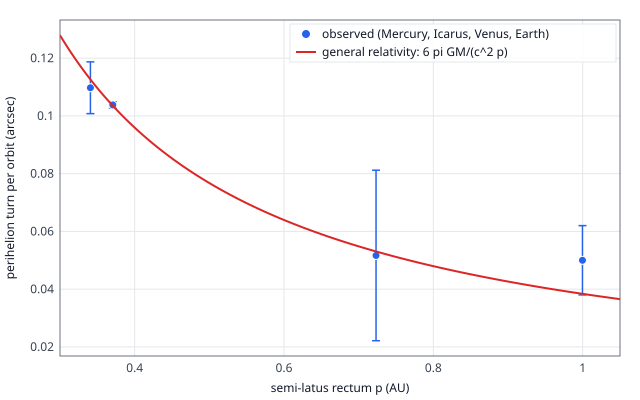

> `legend`: A copy of plot p with new names for its curves in the legend.

In [11]:
legend(labels(show(scatter(pw, [p w], sw), plot(0.03838/p, p, 0.3, 1.05)), "semi-latus rectum p (AU)", "perihelion turn per orbit (arcsec)"), "observed (Mercury, Icarus, Venus, Earth)", "general relativity: 6 pi GM/(c^2 p)")

## 5. What discovery can and cannot do

Looking back over the four lessons:

* **Found from data:** Kepler's three laws, the inverse-square law with $GM_\odot = 4\pi^2$ AU³/year², the Binet
  equation $u'' + u = GM/h^2$, and, for the anomaly, the $1/p$ scaling, the $u^2$ term and its size, $\epsilon \approx 4.4$ km. Each step was a search over simple formulas built from blocks we chose, ranked by fit and simplicity.
* **Not found from data:** why. General relativity cannot be fitted from planetary data. Its central idea, that gravity
  is the geometry of spacetime, is a conceptual leap; the $u^2$ term is one small consequence of it, and the same
  theory predicts light bending, gravitational redshift, black holes and gravitational waves, which no fit to orbits
  would hint at. What data *can* do is decide between theories, as `check` did here: Einstein's has no free constant
  and passes; a Newtonian "Vulcan" or an arbitrary $1/r^4$ force would need a constant tuned for the purpose, and then
  makes wrong predictions elsewhere.
* **Derived:** the algebra from Einstein's orbit equation to $6\pi GM/(c^2p)$, under stated approximations.

This is how physics actually works: patterns in data (Kepler), an explanation that unifies them (Newton), a crack in the
explanation found by better data (Le Verrier), a pattern in the crack (the $1/p$ scaling), and a new theory that
predicts it without being told (Einstein). Galileo can help with every step except the leap.

To go further: the [general relativity path](../general-relativity/README.md) derives the orbit equation from the
Schwarzschild metric and follows the same theory to light bending, black holes and gravitational waves.

## Sources

Numbers in square brackets in the text refer to this list.

1. C. W. Misner, K. S. Thorne and J. A. Wheeler, *Gravitation*, W. H. Freeman (1973), chapter 25 and §40.5
   (perihelion shift); S. Weinberg, *Gravitation and Cosmology*, Wiley (1972), section 8.6.
2. IAU 2015 Resolution B3, nominal solar mass parameter $GM_\odot = 1.3271244 \times 10^{20}$ m³/s², divided by
   $c^2 = 8.98755 \times 10^{16}$ m²/s², gives 1476.6 m. [arXiv:1510.07674](https://arxiv.org/abs/1510.07674)
3. NASA Goddard, *Mercury Fact Sheet*,
   [nssdc.gsfc.nasa.gov/planetary/factsheet/mercuryfact.html](https://nssdc.gsfc.nasa.gov/planetary/factsheet/mercuryfact.html).
4. Einstein to Paul Ehrenfest, 17 January 1916, *The Collected Papers of Albert Einstein*, Vol. 8, Doc. 182,
   Princeton University Press (1998); quoted in A. Pais, *'Subtle is the Lord...'*, Oxford University Press (1982),
   p. 253.

Back to the [index](README.md).